# W09A Formulating simple loss functions

In [5]:
import torch
import numpy as np
import matplotlib.pyplot as plt

### Linear Fit

tensor([1., 1., 1., 1., 1., 1., 1., 1.], grad_fn=<AddBackward0>)
Step 0, Loss: 11.171249389648438
Step 1000, Loss: 0.22658193111419678
Step 2000, Loss: 0.22652524709701538
Step 3000, Loss: 0.22652529180049896
Step 4000, Loss: 0.22652526199817657


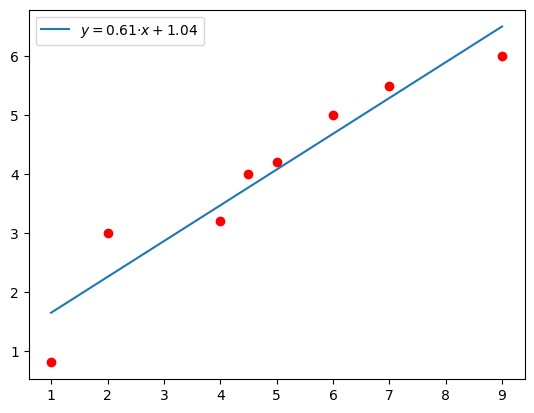

In [ ]:
xs = torch.tensor([1., 2, 4, 4.5, 5, 6, 7, 9])
ys = torch.tensor([0.8, 3, 3.2, 4, 4.2, 5, 5.5, 6])

class Line(torch.nn.Module):
	def __init__(self, w=0, b=1):
		super().__init__()
		self.w = torch.nn.Parameter(torch.tensor(float(w)))
		self.b = torch.nn.Parameter(torch.tensor(float(b)))
		# converting into parameter type to tell the module
		# that we want gradients

	def forward(self, x):
		y = self.w * x + self.b
		return y

line = Line()
# with w=0, b=1, line(xs) should be a tensor of 1's
print(line(xs))

# now we can define a loss function to optimize with our Line class:
optimizer = torch.optim.Adam(line.parameters(), lr=0.01)
steps = 5000
for step in range(steps):
	optimizer.zero_grad() # wipe the previous calculated gradients
	ys_model = line(xs)
	loss = torch.mean((ys_model - ys)**2)
	loss.backward()
	optimizer.step()
	if step % 1000 == 0:
		print(f'Step {step}, Loss: {loss.item ()}')

fig, ax = plt.subplots()

ax.scatter(xs, ys, c='r')
with torch.no_grad():
	ax.plot(xs, line(xs), label=r'$y=$'+f'{line.w.item():.2f}'+r'$\cdot x+$'+f'{line.b.item():.2f}')
ax.legend()


### Center of mass in 1D

In [ ]:
class CM(torch.nn.Module):
	def __init__(self, cm =1):
		super().__init__ ()
		self.cm = torch.nn. Parameter (torch.tensor(float(cm)))
	def forward(self, x):
		distances = x - self.cm
		return distances

xs = torch.rand(10) * 2
xs -= torch.mean(xs)
xs += 5  # mean of 5

cm = CM()
optimizer = torch.optim.Adam(cm.parameters(), lr =0.01)
steps = 2000
for step in range(steps):
	optimizer.zero_grad() # wipe the previous calculated gradients
	ds = cm(xs)
	loss = torch.mean(ds**2)
	loss.backward()
	optimizer.step()
	if step % 200 == 0:
		print(f'Step {step}, Loss: {loss.item ()}')

# printing "all" named parameters in 'cm'
for name , parameter in cm.named_parameters():
	print(name, ':', parameter.data)
# center of mass should be 5 (the mean)

Step 0, Loss: 16.361553192138672
Step 200, Loss: 5.32202672958374
Step 400, Loss: 1.4286903142929077
Step 600, Loss: 0.5084120035171509
Step 800, Loss: 0.37382036447525024
Step 1000, Loss: 0.36215463280677795
Step 1200, Loss: 0.3615698218345642
Step 1400, Loss: 0.3615533709526062
Step 1600, Loss: 0.3615531623363495
Step 1800, Loss: 0.36155322194099426
cm : tensor(5.0000)


### Roots of function

In [ ]:
class FZero(torch.nn.Module):
	'''
	given f(x), find x0 such that f(x0)=0
	i.e find the root of the function
	'''
	def __init__(self, f, x0=0):
		super().__init__()
		self.f = f
		self.x0 = torch.nn. Parameter(torch.tensor(float(x0)))
	def forward(self):
		return self.f(self.x0)

# the function for which we seek the nodes
f = lambda x: (x -8) *(x+2)
# instantiation
fzero = FZero(f)
# f(x0) according to the forward-method with x0=0 should be -16
print(fzero())

optimizer = torch.optim.Adam(fzero.parameters(), lr =0.01)

steps = 2000
for step in range(steps):
	optimizer.zero_grad() # wipe the previous calculated gradients
	loss = fzero()**2
	loss.backward()
	optimizer.step()
	if step % 200 == 0:
		print(f'Step {step}, Loss: {loss.item ()}')

# check the root is correct
root = fzero.x0.item()
print(f'f(x0)={f(root):.4f}')

tensor(-16., grad_fn=<MulBackward0>)
Step 0, Loss: 256.0
Step 200, Loss: 10.921854972839355
Step 400, Loss: 0.003035914385691285
Step 600, Loss: 3.139174031829839e-09
Step 800, Loss: 9.094945629950502e-11
Step 1000, Loss: 9.094945629950502e-11
Step 1200, Loss: 9.094945629950502e-11
Step 1400, Loss: 9.094945629950502e-11
Step 1600, Loss: 9.094945629950502e-11
Step 1800, Loss: 6.963317422670201e-11
f(x0)=-0.0000


# W09B The gradient and a first steepest descent

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt

[Text(0.5, 0, '$x_1$'), Text(0, 0.5, '$x_2$')]

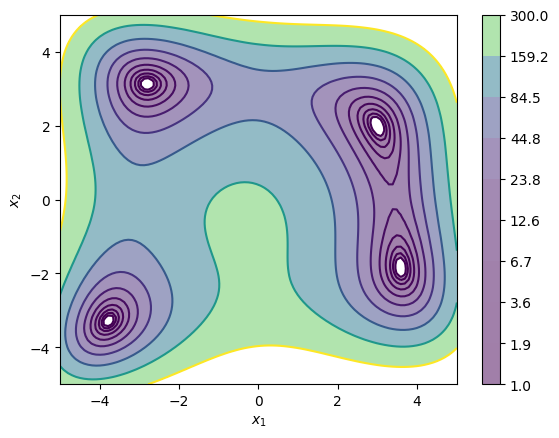

In [2]:
f = lambda x1, x2 : (x1**2 + x2 -11)**2 + (x1 + x2**2 - 7)**2

vals = np.linspace(-5,5,100)
x1d, x2d = np.meshgrid(vals ,vals)
yd = f(x1d, x2d)

fig, ax = plt.subplots()
levels = np.logspace(0, np.log10(300), 10)
ax.contour(x1d, x2d, yd, levels=levels)
color_map = ax.contourf(x1d, x2d, yd, levels=levels, alpha=0.5)
fig.colorbar(color_map, ax=ax)
ax.set(xlabel='$x_1$', ylabel='$x_2$')

### The gradients

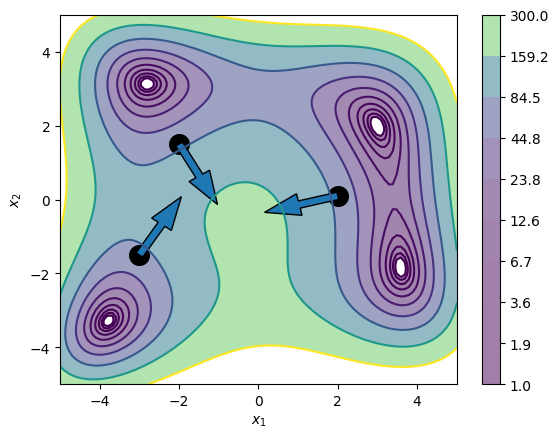

In [ ]:
f = lambda x1, x2 : (x1**2 + x2 -11)**2 + (x1 + x2**2 - 7)**2

vals = np.linspace(-5,5,100)
x1d, x2d = np.meshgrid(vals ,vals)
yd = f(x1d, x2d)

fig, ax = plt.subplots()
levels = np.logspace(0, np.log10(300), 10)
ax.contour(x1d, x2d, yd, levels=levels)
color_map = ax.contourf(x1d, x2d, yd, levels=levels, alpha=0.5)
fig.colorbar(color_map, ax=ax)
ax.set(xlabel='$x_1$', ylabel='$x_2$')


### ADDING GRADIENTS HERE ###
for P0 in[[-2, 1.5], [2, .1], [-3, -1.5]]:
	P0 = torch.tensor(P0, requires_grad=True)
	y = f(*P0)  # forward pass
	y.backward() # backward pass
	grad_of_y = P0.grad  # get gradient
	P0 = P0.detach()
	v = grad_of_y /np.linalg.norm(grad_of_y)
	ax.scatter(*P0,s=200,c='k')
	ax.arrow(*P0,*v,width =0.2)


### Optimizing manually: Steepest descent

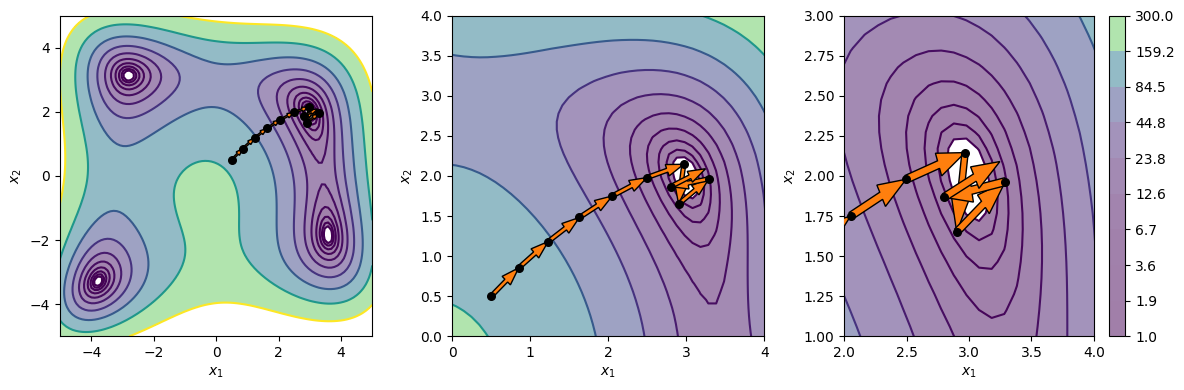

In [ ]:
fig, axes = plt.subplots(1,3,figsize=(12,4))

P0 = torch.tensor ([0.5, 0.5], requires_grad=True)

# if we don't zero the gradient, they will accumilate, and then the normalization is wrong
# so the gradient we see is wrong
REMEMBER_ZEROING_GRADIENT = True

for _ in range(10):
	if REMEMBER_ZEROING_GRADIENT and P0.grad is not None:
		P0.grad.zero_()
	y = f(*P0) # YOUR CODE forward calculation of function value
	y.backward() # YOUR CODE backward calculation of gradient
	grad = P0.grad

	with torch.no_grad ():
		v = grad / torch.norm(grad)
		step_size = 0.5
		for ax in axes:
			ax.scatter(*P0, s=30, c='k', zorder=11)
			ax.arrow(*P0, *(-v*step_size), width=0.05, length_includes_head=True, facecolor='C1', edgecolor='k', zorder=10)
		P0 -= v * step_size

for ax in axes:
	ax.contour(x1d, x2d, yd, levels=levels)
	color_map = ax.contourf(x1d, x2d, yd, levels=levels, alpha=0.5)
	ax.set(xlabel='$x_1$', ylabel='$x_2$')

axes[1].set_xlim(0,4)
axes[1].set_ylim(0,4)
axes[2].set_xlim(2,4)
axes[2].set_ylim(1,3)
fig.colorbar(color_map, ax=axes[-1])
fig.tight_layout()

### Gradient descent

Now we won't normalize the gradient and take fixed steps, we will step along the gradient with the size that it has.

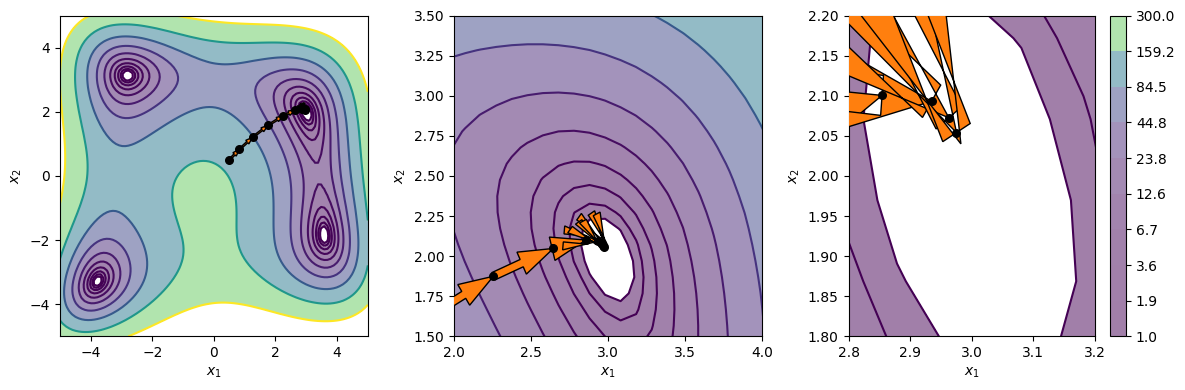

In [ ]:
fig, axes = plt.subplots(1,3,figsize=(12,4))

P0 = torch.tensor ([0.5, 0.5], requires_grad=True)

# if we don't zero the gradient, they will accumilate, and then the normalization is wrong
# so the gradient we see is wrong
REMEMBER_ZEROING_GRADIENT = True

for _ in range(10):
	if REMEMBER_ZEROING_GRADIENT and P0.grad is not None:
		P0.grad.zero_()
	y = f(*P0) # YOUR CODE forward calculation of function value
	y.backward() # YOUR CODE backward calculation of gradient
	grad = P0.grad

	with torch.no_grad ():
		learning_rate = 0.01
		for ax in axes:
			ax.scatter(*P0, s=30, c='k', zorder=11)
			ax.arrow(*P0, *(-learning_rate*grad), width=0.05, length_includes_head=True, facecolor='C1', edgecolor='k', zorder=10)
		P0 -= learning_rate * grad

for ax in axes:
	ax.contour(x1d, x2d, yd, levels=levels)
	color_map = ax.contourf(x1d, x2d, yd, levels=levels, alpha=0.5)
	ax.set(xlabel='$x_1$', ylabel='$x_2$')

axes[1].set_xlim(2,4)
axes[1].set_ylim(1.5,3.5)
axes[2].set_xlim(2.8,3.2)
axes[2].set_ylim(1.8,2.2)
fig.colorbar(color_map, ax=axes[-1])
fig.tight_layout()

### Optimizing with nn.Module

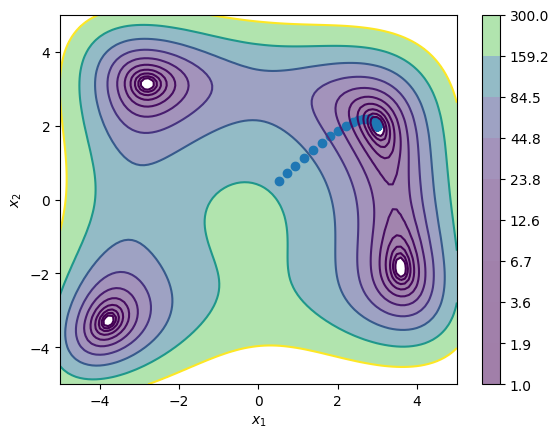

In [ ]:
class ScalarField(torch.nn.Module):
	def __init__(self, f, P0 = [0.5, 0.5]):
		super().__init__()
		self.f = f
		self.P0 = torch.nn.Parameter(torch.tensor(P0))

	def forward(self):
		y = self.f(*self.P0)
		return y

sf = ScalarField(f)# instantiating the class

optimizer = torch.optim.Adam(sf.parameters(), lr=0.01)

step_points = []
steps = 1000
for step in range(steps):
	optimizer.zero_grad()
	loss = sf()  # for forward calc of function value
	loss.backward() # for backward calc of gradient
	optimizer.step()
	if step % 20 == 0:
		step_points.append(sf.P0.data.clone())

fig, ax = plt.subplots()
levels = np.logspace(0, np.log10(300), 10)
ax.contour(x1d, x2d, yd, levels=levels)
color_map = ax.contourf(x1d, x2d, yd, levels=levels, alpha=0.5)
fig.colorbar(color_map, ax=ax)
ax.set(xlabel='$x_1$', ylabel='$x_2$')

xs, ys = zip(*step_points)
ax.scatter(xs, ys)

# W09C Using torch.nn.Model to fit a circle

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt

### A parabula

In [ ]:
class Parabola(torch.nn.Module):
	def __init__(self, a=1, b=1, c=1):
		super().__init__()
		self.a = torch.nn.Parameter(torch.tensor(float(a)))
		self.b = torch.nn.Parameter(torch.tensor(float(b)))
		self.c = torch.nn.Parameter(torch.tensor(float(c)))

	def forward(self, x):
		y = self.a * x**2 + self.b * x + self.c
		return y

### Fitting

Step 0, Loss: 327.3333435058594
Step 1000, Loss: 0.974776566028595
Step 2000, Loss: 0.6094802618026733
Step 3000, Loss: 0.40578362345695496
Step 4000, Loss: 0.20373095571994781
Step 5000, Loss: 0.06466067582368851
Step 6000, Loss: 0.009641281329095364
Step 7000, Loss: 0.0004092402814421803
Step 8000, Loss: 2.1121377358213067e-06
Step 9000, Loss: 3.0089589153625695e-10


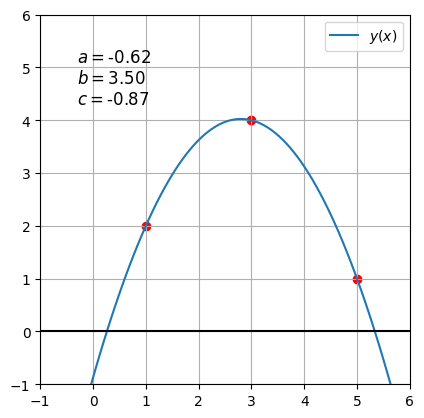

In [ ]:
points = torch.tensor([[1.,2], [3,4], [5,1]])
xs = points[:,0]
ys = points[:,1]

parabola = Parabola()# instantiating the class

optimizer = torch.optim.Adam(parabola.parameters(), lr=0.01)

loss_func = torch.nn.MSELoss ()

steps = 10000
for step in range(steps):
	optimizer.zero_grad() # wipe the previous calculated gradients
	ys_model = parabola(xs)
	# loss = torch.mean((ys_model - ys)**2)  # the true loss function
	loss = loss_func (ys_model, ys)  # for faster computations when theres a lot of data
	loss.backward()
	optimizer.step()
	if step % 1000 == 0:
		print(f'Step {step}, Loss: {loss.item ()}')

fig, ax = plt.subplots()

xspace = torch.linspace(-1, 6, 100)
ax.scatter(xs, ys, c='r')
with torch.no_grad():
	ax.plot(xspace, parabola(xspace), label=r'$y(x)$')
ax.text(0.1, 0.8, r'$a=$'+f'{parabola.a.item():.2f}\n'
				+ r'$b=$'+f'{parabola.b.item():.2f}\n'
				+ r'$c=$'+f'{parabola.c.item():.2f}\n'
				, transform=ax.transAxes, ha='left', va='center', size=12)
ax.legend()
ax.set_ylim(-1,6)
ax.set_xlim(-1,6)
ax.set_aspect('equal')
ax.axhline(0, c='k')
ax.grid()

### Gaussian

In [ ]:
class Gaussian(torch.nn.Module):
	def __init__(self, A=1, x0=1, sigma=1):
		super().__init__()
		self.A = torch.nn.Parameter(torch.tensor(float(A)))
		self.x0 = torch.nn.Parameter(torch.tensor(float(x0)))
		self.sigma = torch.nn.Parameter(torch.tensor(float(sigma)))

	def forward(self, x):
		f = self.A * torch.exp(-(x-self.x0)**2/(2*self.sigma**2))
		return f

Step 0, Loss: 5.6449875831604
Step 1000, Loss: 4.499475210195669e-07
Step 2000, Loss: 3.371288317954857e-11
Step 3000, Loss: 1.0710247792811156e-11
Step 4000, Loss: 3.34428773736406e-12
Step 5000, Loss: 1.0137076724911487e-12
Step 6000, Loss: 2.3211063604998416e-13
Step 7000, Loss: 9.592326932761353e-14
Step 8000, Loss: 2.0132043615180874e-14
Step 9000, Loss: 1.8947806851624636e-14


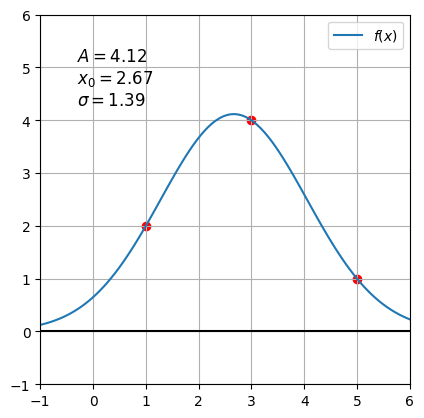

In [ ]:
gauss = Gaussian()# instantiating the class

optimizer = torch.optim.Adam(gauss.parameters(), lr=0.01)

loss_func = torch.nn.MSELoss ()

steps = 10000
for step in range(steps):
	optimizer.zero_grad() # wipe the previous calculated gradients
	ys_model = gauss(xs)
	loss = loss_func (ys_model, ys)
	loss.backward()
	optimizer.step()
	if step % 1000 == 0:
		print(f'Step {step}, Loss: {loss.item ()}')

fig, ax = plt.subplots()

xspace = torch.linspace(-1, 6, 100)
ax.scatter(xs, ys, c='r')
with torch.no_grad():
	ax.plot(xspace, gauss(xspace), label=r'$f(x)$')
ax.text(0.1, 0.8, r'$A=$'+f'{gauss.A.item():.2f}\n'
				+ r'$x_0=$'+f'{gauss.x0.item():.2f}\n'
				+ r'$\sigma=$'+f'{gauss.sigma.item():.2f}\n'
				, transform=ax.transAxes, ha='left', va='center', size=12)
ax.legend()
ax.set_ylim(-1,6)
ax.set_xlim(-1,6)
ax.set_aspect('equal')
ax.axhline(0, c='k')
ax.grid()

### Circle

In [ ]:
class Circle(torch.nn.Module):
	def __init__(self, x0=1, y0=1, r=1):
		super().__init__()
		self.y0 = torch.nn.Parameter(torch.tensor(float(y0)))
		self.x0 = torch.nn.Parameter(torch.tensor(float(x0)))
		self.r = torch.nn.Parameter(torch.tensor(float(r)))

	def forward(self, points):
		# make the function of the circle. If a point lies on the circle, return zero
		xs = points[:, 0]
		ys = points[:, 1]
		return (xs-self.x0)**2 + (ys-self.y0)**2 - self.r**2

Step 0, Loss: 123.0
Step 1000, Loss: 0.00015752340550534427
Step 2000, Loss: 4.6338755055330694e-10
Step 3000, Loss: 1.6052581486292183e-10
Step 4000, Loss: 4.865796654485166e-11
Step 5000, Loss: 1.5916157281026244e-11
Step 6000, Loss: 5.835924191816e-12
Step 7000, Loss: 1.288450791371576e-12
Step 8000, Loss: 3.78956116703702e-13
Step 9000, Loss: 1.515824548129971e-13


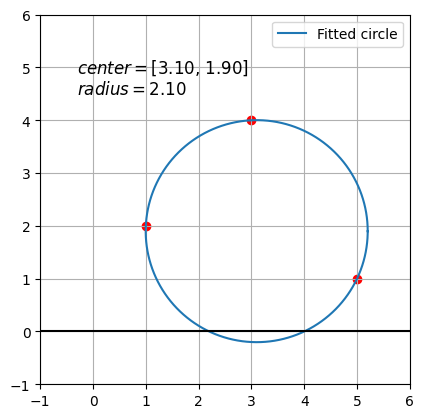

In [ ]:
circle = Circle()# instantiating the class

optimizer = torch.optim.Adam(circle.parameters(), lr=0.01)

loss_func = torch.nn.MSELoss ()

steps = 10000
for step in range(steps):
	optimizer.zero_grad() # wipe the previous calculated gradients
	residuals = circle(points)
	loss = torch.mean(residuals**2)
	loss.backward()
	optimizer.step()
	if step % 1000 == 0:
		print(f'Step {step}, Loss: {loss.item ()}')

fig, ax = plt.subplots()

xspace = torch.linspace(-1, 6, 100)
yspace = torch.linspace(-1, 6, 100)
ax.scatter(xs, ys, c='r')
with torch.no_grad():
	theta = torch.linspace(0, 2 * torch.pi, 300)
	x_circle = circle.x0 + circle.r * torch.cos(theta)
	y_circle = circle.y0 + circle.r * torch.sin(theta)
	# plot with numpy arrays:
	ax.plot(x_circle.numpy(), y_circle.numpy(), label="Fitted circle")

ax.text(0.1, 0.8, r'$center=$'+f'[{circle.x0.item():.2f}, {circle.y0.item():.2f}]\n'
				+ r'$radius=$'+f'{circle.r.item():.2f}\n'
				, transform=ax.transAxes, ha='left', va='center', size=12)
ax.legend()
ax.set_ylim(-1,6)
ax.set_xlim(-1,6)
ax.set_aspect('equal')
ax.axhline(0, c='k')
ax.grid()

# W09D Gaussian fit

In [2]:
import torch
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
class Gaussian(torch.nn.Module):
	def __init__(self, A=1, x0=1, sigma=1):
		super().__init__()
		self.A = torch.nn.Parameter(torch.tensor(float(A)))
		self.x0 = torch.nn.Parameter(torch.tensor(float(x0)))
		self.sigma = torch.nn.Parameter(torch.tensor(float(sigma)))

	def forward(self, x):
		f = self.A * torch.exp(-(x-self.x0)**2/(2*self.sigma**2))
		return f


Step 0, Loss: 0.022890962660312653
Step 1000, Loss: 0.006504060234874487
Step 2000, Loss: 0.006481362972408533
Step 3000, Loss: 0.0064813317731022835
Step 4000, Loss: 0.006481332238763571
Step 5000, Loss: 0.006481332238763571
Step 6000, Loss: 0.006481332238763571
Step 7000, Loss: 0.006481332238763571
Step 8000, Loss: 0.006481332238763571
Step 9000, Loss: 0.006481332238763571


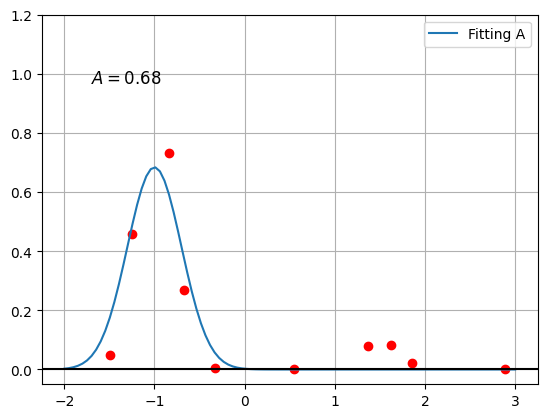

In [ ]:
data = torch.tensor([[-1.493, 0.048],
				[-1.25, 0.459],
				[-0.842, 0.731],
				[-0.676, 0.269],
				[-0.332, 0.004],
				[0.544, 0.],
				[1.363, 0.079],
				[1.621, 0.083],
				[1.853, 0.021],
				[2.892, 0.]])
xs = data[:,0]
ys = data[:, 1]
def fit_gaussian(x0, sigma):
	gaussian = Gaussian(x0=x0, sigma=sigma)
	optimizer = torch.optim.SGD([gaussian.A], lr=0.01) # SGD might require smaller learning rate
	loss_func = torch.nn.MSELoss()

	steps = 10000
	for step in range(steps):
		optimizer.zero_grad() # wipe the previous calculated gradients
		ys_model = gaussian(xs)
		# loss = torch.mean((ys_model - ys)**2)  # the true loss function
		loss = loss_func(ys_model, ys)  # for faster computations when theres a lot of data
		loss.backward()
		optimizer.step()
		if step % 1000 == 0:
			print(f'Step {step}, Loss: {loss.item ()}')

	fig, ax = plt.subplots()

	xspace = torch.linspace(-2, 3, 100)
	ax.scatter(xs, ys, c='r')
	with torch.no_grad():
		ax.plot(xspace, gaussian(xspace), label='Fitting A')
	ax.text(0.1, 0.8, r'$A=$'+f'{gaussian.A.item():.2f}\n',
			transform=ax.transAxes, ha='left', va='center', size=12)
	ax.legend()
	ax.set_ylim(-0.05,1.2)
	ax.axhline(0, c='k')
	ax.grid()

fit_gaussian(x0=-1, sigma=0.3)

Step 0, Loss: 0.24289950728416443
Step 1000, Loss: 0.08209605515003204
Step 2000, Loss: 0.08202050626277924
Step 3000, Loss: 0.08202046900987625
Step 4000, Loss: 0.08202046900987625
Step 5000, Loss: 0.08202046900987625
Step 6000, Loss: 0.08202046900987625
Step 7000, Loss: 0.08202046900987625
Step 8000, Loss: 0.08202046900987625
Step 9000, Loss: 0.08202046900987625


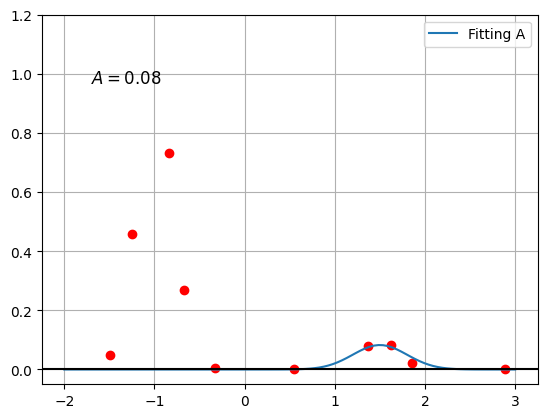

In [25]:
fit_gaussian(x0=1.5, sigma=0.3)

### Fit all three parameters, play with different initializations

Step 0, Loss: 0.24412576854228973
Step 1000, Loss: 0.0688854232430458
Step 2000, Loss: 0.06888388097286224
Step 3000, Loss: 0.06888388097286224
Step 4000, Loss: 0.06888388097286224
Step 5000, Loss: 0.06888388097286224
Step 6000, Loss: 0.06888388097286224
Step 7000, Loss: 0.06888388097286224
Step 8000, Loss: 0.06888388097286224
Step 9000, Loss: 0.06888388097286224


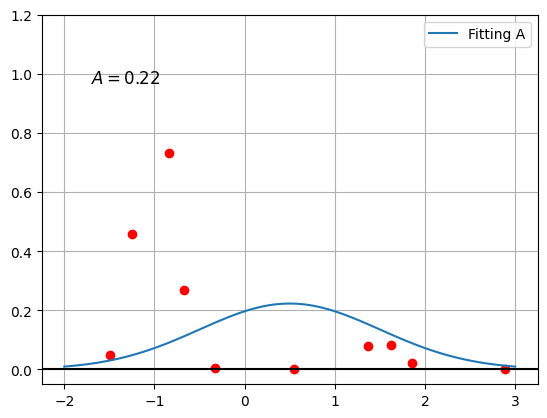

In [27]:
fit_gaussian(x0=0.5, sigma=1)

# W09E Spring models and catenary

In [12]:
import torch
import numpy as np
import matplotlib.pyplot as plt

### A bead between two springs

Step 0, Loss: 4.276142120361328
Step 1000, Loss: 0.011822748929262161
Step 2000, Loss: 0.0008240276365540922
Step 3000, Loss: 0.00014817423652857542
Step 4000, Loss: 3.7647281715180725e-05
Step 5000, Loss: 1.1260937753831968e-05
Step 6000, Loss: 3.6729779822053388e-06
Step 7000, Loss: 1.2580132988659898e-06
Step 8000, Loss: 4.434497213878785e-07
Step 9000, Loss: 1.5883460946497507e-07


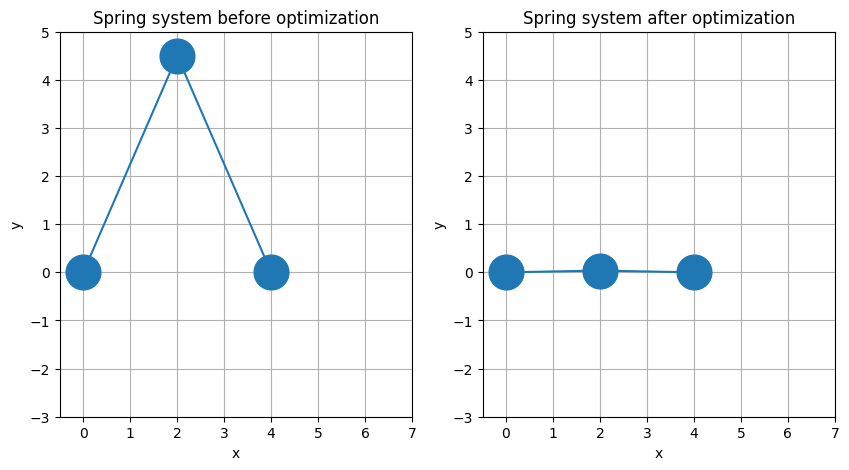

In [ ]:
class SimpleSpringSystem(torch.nn.Module):

	k = 0.5

	def __init__(self, x=2, y=4.5, xv=0, yv=0, xh=4, yh=0):
		super().__init__()
		self.x = torch.nn.Parameter(torch.tensor(float(x)))
		self.y = torch.nn.Parameter(torch.tensor(float(y)))
		self.xv = xv
		self.yv = yv
		self.xh = xh
		self.yh = yh

	def forward(self):
		rest_length = 2.0
		energyv = 1/2 * self.k * (torch.sqrt((self.x-self.xv)**2 + (self.y-self.yv)**2) - rest_length)**2
		energyh = 1/2 * self.k * (torch.sqrt((self.x-self.xh)**2 + (self.y-self.yh)**2) - rest_length)**2
		energy = energyv + energyh
		return energy

model = SimpleSpringSystem()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01) # SGD might require smaller learning rate

fig, axes = plt.subplots(1,2,figsize=(10,5))
axes[0].plot([0,2,4],[0,4.5,0], '.-', ms=50)
axes[0].set_title('Spring system before optimization')

steps = 10000
for step in range(steps):
	optimizer.zero_grad() # wipe the previous calculated gradients
	energy = model()  # let this be the loss. Calls 'forward' in the class, i.e. loss=energy
	energy.backward()
	optimizer.step()
	if step % 1000 == 0:
		print(f'Step {step}, Loss: {energy.item()}')

axes[1].plot([0, model.x.item(), 4], [0, model.y.item(), 0], '.-', ms=50)
axes[1].set_title('Spring system after optimization')

for ax in axes:
	ax.set_xlabel('x')
	ax.set_ylabel('y')
	ax.set_xlim(-0.5, 7)
	ax.set_ylim(-3, 5)
	ax.grid()

### A string of beads

Now generalize the solution to several beads

C:\Users\emilk\AppData\Local\Temp\ipykernel_24704\2612790458.py:7: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.pos = torch.nn.Parameter(torch.tensor(pos))


Step 0, Loss: 2.7732272148132324
Step 1000, Loss: 4.337863401815412e-12
Step 2000, Loss: 6.998845947236987e-13
Step 3000, Loss: 2.2737367544323206e-13
Step 4000, Loss: 5.684341886080802e-14
Step 5000, Loss: 1.4210854715202004e-14
Step 6000, Loss: 0.0
Step 7000, Loss: 0.0
Step 8000, Loss: 0.0
Step 9000, Loss: 0.0


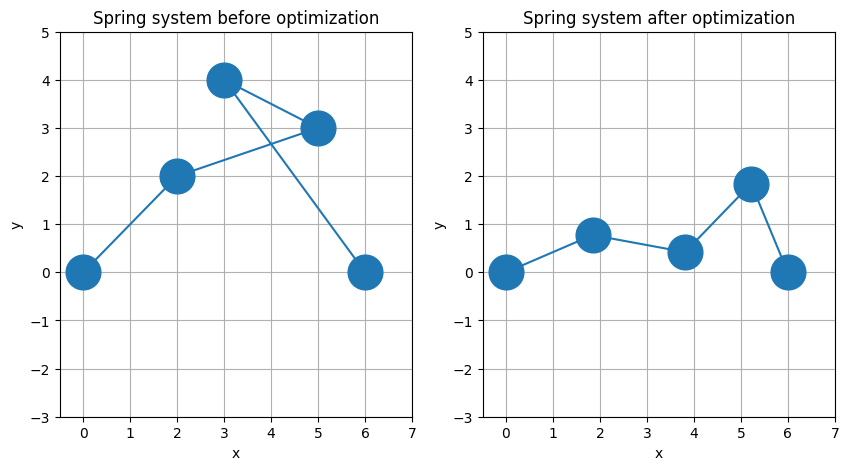

In [ ]:
class SpringSystem(torch.nn.Module):
	k = 0.5
	def __init__(self, pos):
		super().__init__()
		self.pos = torch.nn.Parameter(torch.tensor(pos)) 

	def forward(self):
		rest_length = 2.0
		distances = torch.linalg.vector_norm(self.pos[1:]-self.pos[:-1], dim=1)
		energy = torch.sum(0.5 * self.k * (distances - rest_length)**2)
		return energy

pos = torch.tensor([[0.,0], [2,2], [5,3], [3, 4], [6,0]])
model = SpringSystem(pos)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01) # SGD might require smaller learning rate

fig, axes = plt.subplots(1,2,figsize=(10,5))
xs = pos[:, 0]
ys = pos[:, 1]
axes[0].plot(xs, ys, '.-', ms=50)
axes[0].set_title('Spring system before optimization')

steps = 10000
for step in range(steps):
	optimizer.zero_grad() # wipe the previous calculated gradients
	energy = model()  # let this be the loss. Calls 'forward' in the class, i.e. loss=energy
	energy.backward()
	# zero the gradients of end beads:
	with torch.no_grad():
		model.pos.grad[[0,-1]] = 0
	optimizer.step()
	if step % 1000 == 0:
		print(f'Step {step}, Loss: {energy.item()}')

xs = model.pos.data[:, 0]
ys = model.pos.data[:, 1]
axes[1].plot(xs, ys, '.-', ms=50)
axes[1].set_title('Spring system after optimization')

for ax in axes:
	ax.set_xlabel('x')
	ax.set_ylabel('y')
	ax.set_xlim(-0.5, 7)
	ax.set_ylim(-3, 5)
	ax.grid()

### The catenary

C:\Users\emilk\AppData\Local\Temp\ipykernel_24704\2612790458.py:7: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.pos = torch.nn.Parameter(torch.tensor(pos))


Step 0, Loss: 64.46454620361328
Step 1000, Loss: -2.0000171661376953
Step 2000, Loss: -6.109465599060059
Step 3000, Loss: -6.126163005828857
Step 4000, Loss: -6.126163005828857
Step 5000, Loss: -6.126163482666016
Step 6000, Loss: -6.126163005828857
Step 7000, Loss: -6.126162528991699
Step 8000, Loss: -6.126162528991699
Step 9000, Loss: -6.126163482666016


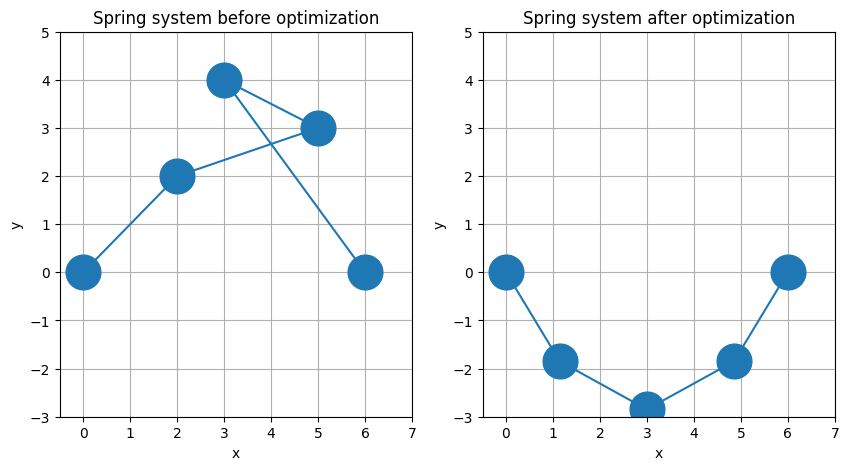

In [ ]:
class SpringSystemWithGravity(SpringSystem):
	k = 10  # increase spring constant to minimize stretching.
	def forward(self):
		spring_energy = super().forward()
		gravitational_energy = torch.sum(1 * 1 * self.pos[:,1])  # m*g*y, but use arbitrary units
		return spring_energy + gravitational_energy

pos = torch.tensor([[0.,0], [2,2], [5,3], [3, 4], [6,0]])
model = SpringSystemWithGravity(pos)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01) # SGD might require smaller learning rate

fig, axes = plt.subplots(1,2,figsize=(10,5))
xs = pos[:, 0]
ys = pos[:, 1]
axes[0].plot(xs, ys, '.-', ms=50)
axes[0].set_title('Spring system before optimization')

steps = 10000
for step in range(steps):
	optimizer.zero_grad() # wipe the previous calculated gradients
	energy = model()  # let this be the loss. Calls 'forward' in the class, i.e. loss=energy
	energy.backward()
	# zero the gradients of end beads:
	with torch.no_grad():
		model.pos.grad[[0,-1]] = 0
	optimizer.step()
	if step % 1000 == 0:
		print(f'Step {step}, Loss: {energy.item()}')

xs = model.pos.data[:, 0]
ys = model.pos.data[:, 1]
axes[1].plot(xs, ys, '.-', ms=50)
axes[1].set_title('Spring system after optimization')

for ax in axes:
	ax.set_xlabel('x')
	ax.set_ylabel('y')
	ax.set_xlim(-0.5, 7)
	ax.set_ylim(-3, 5)
	ax.grid()

# W09F Lennard-Jones-Gauss systems

In [13]:
import torch
import numpy as np
import matplotlib.pyplot as plt

In [14]:
class LennardJonesGauss():
	def __init__(self, eps=1, sigma_squared=0.02, r0=1.7):
		super().__init__()
		self.eps = eps
		self.sigma_squared = sigma_squared
		self.r0 = r0

	def V(self, r):
		return r**(-12) - 2*r**(-6) - self.eps * torch.exp(-(r-self.r0)**2/(2*self.sigma_squared))

class LJGSystem(torch.nn.Module):
	def __init__(self, calc, positions):
		super().__init__()
		self.calc = calc
		self.positions = torch.nn.Parameter(positions)
											   
	def forward(self):
		return torch.sum(self.calc.V(torch.pdist(self.positions)))

	def draw(self, ax):
		ax.scatter(self.positions.data[:, 0],
				   self.positions.data[:, 1], s=100)

In [15]:
pos = torch.tensor([[4.065,  5.93],
					[3.211, 5.465],
					[5.711,   4.9],
					[6.567, 5.374],
					[4.113, 6.903],
					[5.741, 5.879],
					[5.662, 3.924],
					[4.893, 5.411],
					[4.844, 4.443],
					[4.036, 4.953],
					[6.539, 4.384],
					[4.931, 6.382]])
calcLJG = LennardJonesGauss()
systemLJG = LJGSystem(calcLJG, pos)
energy = systemLJG()
energy.item()

-40.66716384887695

### Search

Step 0, Loss: 14750.7158203125
Step 2000, Loss: -30.120786666870117
Step 4000, Loss: -30.120784759521484
Step 6000, Loss: -30.12067985534668
Step 8000, Loss: -30.120893478393555
Step 0, Loss: 365747437568.0
Step 2000, Loss: -29.85515594482422
Step 4000, Loss: -29.85515594482422
Step 6000, Loss: -29.854398727416992
Step 8000, Loss: -29.855152130126953
Step 0, Loss: 524834624.0
Step 2000, Loss: -33.469505310058594
Step 4000, Loss: -33.46949005126953
Step 6000, Loss: -33.46925354003906
Step 8000, Loss: -33.469364166259766
Step 0, Loss: 189619.28125
Step 2000, Loss: -34.30829620361328
Step 4000, Loss: -34.30830764770508
Step 6000, Loss: -34.30824279785156
Step 8000, Loss: -34.30830764770508
Step 0, Loss: 488440832.0
Step 2000, Loss: -41.70026779174805
Step 4000, Loss: -41.70038986206055
Step 6000, Loss: -41.70036315917969
Step 8000, Loss: -41.70030975341797


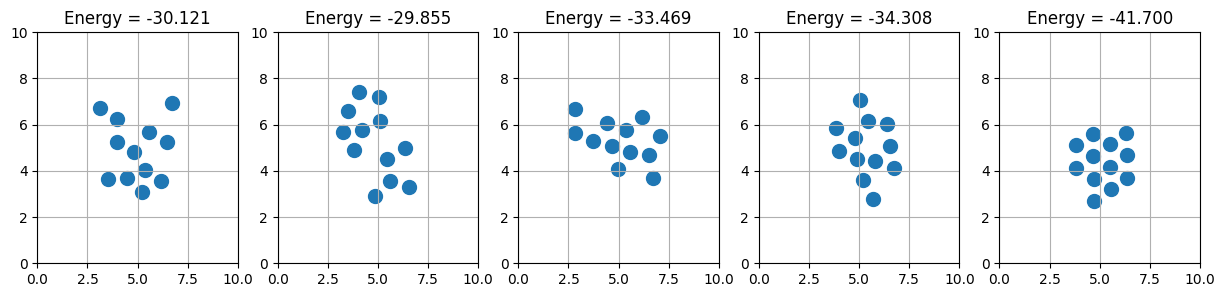

In [16]:
fig, axes = plt.subplots(1,5,figsize=(15,3))

for ax in axes:
	points = 3 + 4 * torch.rand(12,2)
	model = LJGSystem(calcLJG, points)
	optimizer = torch.optim.Adam(model.parameters(), lr=0.005)
	
	steps = 10000
	for step in range(steps):
		optimizer.zero_grad() # wipe the previous calculated gradients
		energy = model()
		energy.backward()
		# to evade too large gradients for optimizer to handle, clip them like this
		torch.nn.utils.clip_grad_value_(model.parameters(), clip_value=0.5)
		optimizer.step()
		if step % 2000 == 0:
			print(f'Step {step}, Loss: {energy.item()}')

	model.draw(ax)
	ax.set_xlim(0, 10)
	ax.set_ylim(0, 10)
	ax.set_title(f'Energy = {energy.item():.3f}')
	ax.grid()


# W09G Equilibrium distributions for a double-well potential

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch

In [2]:
class DoubleWellPotential():
	def __init__(self, x1=-2, x2=2, k1=8, k2=8, alpha=10, deltaE=2):
		self.x1 = x1
		self.x2 = x2
		self.k1 = k1
		self.k2 = k2
		self.alpha=alpha
		self.deltaE = deltaE

	def potential_energy(self, x):
		pot1 = 1/2 * self.k1 * (x - self.x1)**2
		pot2 = 1/2 * self.k2 * (x - self.x2)**2 + self.deltaE
		pot_tot = -1/self.alpha * torch.log(torch.exp(-self.alpha*pot1) + torch.exp(-self.alpha*pot2))
		return pot_tot

	def __call__(self, x):
		return self.potential_energy(x)

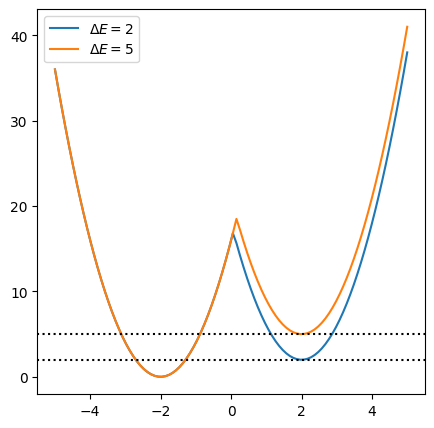

In [3]:
fig, ax = plt.subplots(1,1,figsize=(5,5))

pot_dE2 = DoubleWellPotential(deltaE=2)
pot_dE5 = DoubleWellPotential(deltaE=5)
xs = torch.linspace(-5, 5, 100, dtype=torch.float64)
ax.plot(xs, pot_dE2(xs), label=r'$\Delta E=2$')
ax.plot(xs, pot_dE5(xs), label=r'$\Delta E=5$')
ax.axhline(2, c='k', ls=':')
ax.axhline(5, c='k', ls=':')
ax.legend()

The two minima are $x_1=-2$ and $x_2=2$. $\Delta E$ shifts the second well potential up by that amount

### Metropolis Monte Carlo

skip for now, repetition of week 6

### Softmax and a trainable probability density

In [4]:
class GridSpace():
	def __init__(self, potential, xmin=-5, xmax=5, delta_x=0.1):
		self.potential = potential
		self.delta_x = delta_x
		self.xmin = xmin
		self.xmax = xmax

		self.grid = torch.arange(self.xmin, self.xmax + delta_x, self.delta_x)
		self.logits = torch.ones_like(self.grid)
		self.p = torch.nn.functional.softmax(self.logits, dim=0) / self.delta_x

	@property
	def entropy(self):
		return -torch.sum(self.p * torch.log(self.p)*self.delta_x)

	@property
	def mean_potential_energy(self):
		return torch.sum(self.p * self.potential(self.grid) * self.delta_x)

pot = DoubleWellPotential()
system = GridSpace(pot)
system.mean_potential_energy

tensor(inf)

### Minimum free energy

In [5]:
class MinFreeEnergyDistribution(torch.nn.Module):
	def __init__(self, xs, potential1D, kT):
		super().__init__ ()
		self.delta_x = xs[1] - xs[0]
		self.Vs = torch.tensor(potential1D(xs), dtype=torch.float64)
		self.kT = kT
		self.logits = torch.nn.Parameter(torch.ones_like(self.Vs))

	def forward(self):
		p = torch.nn.functional.softmax(self.logits, dim=0) / self.delta_x
		entropy = -torch.sum(p * torch.log(p+1e-8)) * self.delta_x
		energy = torch.sum(p * self.Vs) * self.delta_x  # mean potential energy
		free_energy = energy - self.kT*entropy  # free energy
		self.energy = energy
		return free_energy, p

pot = DoubleWellPotential()
xs = torch.arange(-5, 5.1, 0.1, dtype=torch.float64)
assert len(xs) == 101
system = MinFreeEnergyDistribution(xs, pot, kT=0.15)

optimizer = torch.optim.Adam(system.parameters(), lr=0.01)
steps = 20000
for step in range(steps):
	optimizer.zero_grad() # wipe the previous calculated gradients
	free_energy, p = system()
	free_energy.backward()
	optimizer.step()
	if step % 2000 == 0:
		print(f'Step {step}, Free Energy: {free_energy}')

C:\Users\emilk\AppData\Local\Temp\ipykernel_36468\4110055043.py:5: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.Vs = torch.tensor(potential1D(xs), dtype=torch.float64)


Step 0, Free Energy: 10.247179101428115
Step 2000, Free Energy: 0.1751553351022198
Step 4000, Free Energy: 0.16405908458085353
Step 6000, Free Energy: 0.1616647053082646
Step 8000, Free Energy: 0.16084211550909217
Step 10000, Free Energy: 0.1605728782194912
Step 12000, Free Energy: 0.16045995977212707
Step 14000, Free Energy: 0.16042352705338384
Step 16000, Free Energy: 0.16040956889200472
Step 18000, Free Energy: 0.16040409018947394


C:\Users\emilk\AppData\Local\Temp\ipykernel_36468\4110055043.py:5: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.Vs = torch.tensor(potential1D(xs), dtype=torch.float64)


Step 0, Free Energy: 8.744031141577425
Step 2000, Free Energy: 0.13998872807469281
Step 4000, Free Energy: 0.1269237331937707
Step 6000, Free Energy: 0.12411011153185475
Step 8000, Free Energy: 0.12323997377931262
Step 10000, Free Energy: 0.12293982237083195
Step 12000, Free Energy: 0.12283246746578441
Step 14000, Free Energy: 0.12279362219946904
Step 16000, Free Energy: 0.12277954422099768
Step 18000, Free Energy: 0.12277464712234742
Step 0, Free Energy: 8.512777609292703
Step 2000, Free Energy: 0.0806260613366876
Step 4000, Free Energy: 0.06758867406572344
Step 6000, Free Energy: 0.06481930745900755
Step 8000, Free Energy: 0.06396966500013113
Step 10000, Free Energy: 0.06367841185011192
Step 12000, Free Energy: 0.06357482071948573
Step 14000, Free Energy: 0.06353754995224614
Step 16000, Free Energy: 0.06352413942159463
Step 18000, Free Energy: 0.06351948917491002
Step 0, Free Energy: 8.281524077007983
Step 2000, Free Energy: 0.010780980336654866
Step 4000, Free Energy: -0.00216788136

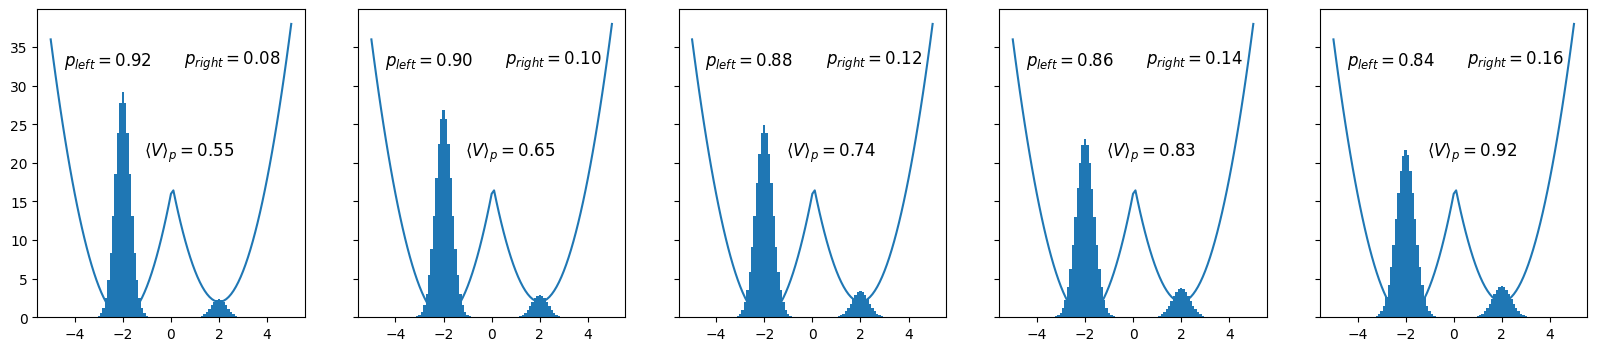

In [6]:
fig, axes = plt.subplots(1,5,figsize=(20,4), sharey=True)

for kT, ax in zip([0.8, 0.9, 1.0, 1.1, 1.2], axes):
	pot = DoubleWellPotential()
	xs = torch.arange(-5, 5.1, 0.1, dtype=torch.float64)
	system = MinFreeEnergyDistribution(xs, pot, kT=kT)

	optimizer = torch.optim.Adam(system.parameters(), lr=0.01)
	steps = 20000
	for step in range(steps):
		optimizer.zero_grad() # wipe the previous calculated gradients
		free_energy, p = system()
		free_energy.backward()
		optimizer.step()
		if step % 2000 == 0:
			print(f'Step {step}, Free Energy: {free_energy}')
	p_left = torch.sum(p[:51])*0.1
	p_right = torch.sum(p[51:101])*0.1
	ax.bar(xs.detach().numpy(), p.detach().numpy()*25, width=0.1)
	ax.text(0.1, 0.8, r'$p_{left}=$'+f'{p_left:.2f}\n',
		transform=ax.transAxes, ha='left', va='center', size=12)
	ax.text(0.55, 0.8, r'$p_{right}=$'+f'{p_right:.2f}\n',
		transform=ax.transAxes, ha='left', va='center', size=12)
	ax.text(0.4, 0.5, r'$\langle V \rangle_p=$'+f'{system.energy:.2f}\n',
		transform=ax.transAxes, ha='left', va='center', size=12)
	ax.plot(xs, pot(xs))
	

This matches the solution found with metropolis monte carlo (trust!).

### Maximum entropy at fixed mean energy

Before we optimized the free energy to find the distribution. Now we maximize the **entropy** while fixing the mean energy, and use that as the target value.

In [7]:
class MinEntropyDistribution(torch.nn.Module):
	def __init__(self, xs, potential1D, kT, l=1):
		super().__init__ ()
		self.l = l
		self.delta_x = xs [1] - xs [0]
		self.Vs = torch.tensor(potential1D(xs), dtype=torch.float64)
		self.kT = kT
		self.logits = torch.nn.Parameter(torch.ones_like(self.Vs))

	def forward(self):
		p = torch.nn.functional.softmax(self.logits, dim=0) / self.delta_x
		entropy = -torch.sum(p * torch.log(p+1e-8)) * self.delta_x
		self.entropy = entropy
		energy = torch.sum(p * self.Vs) * self.delta_x  # mean potential energy
		self.energy = energy

		Z = torch.sum(torch.exp(-self.Vs/self.kT))
		p_boltzmann = 1/Z * torch.exp(-self.Vs/self.kT)
		energy_target = torch.sum(p_boltzmann * self.Vs)  # mean potential energy
		self.energy_target = energy_target

		loss = -entropy + self.l * (energy - energy_target)**2  # free energy
		
		return loss, p

C:\Users\emilk\AppData\Local\Temp\ipykernel_36468\1374279858.py:6: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.Vs = torch.tensor(potential1D(xs), dtype=torch.float64)


Step 0, Loss: 30252.2835895134
Step 2000, Loss: -0.3233815507827813
Step 4000, Loss: -0.3627124896925172
Step 6000, Loss: -0.4124623602120057
Step 8000, Loss: -0.4574834477644667
Step 10000, Loss: -0.49373437228607414
Step 12000, Loss: -0.5178565286547601
Step 14000, Loss: -0.5295468536619254
Step 16000, Loss: -0.534436992247126
Step 18000, Loss: -0.536318967626857
Step 0, Loss: 29689.56796946518
Step 2000, Loss: -0.4528876361832622
Step 4000, Loss: -0.4848835850345477
Step 6000, Loss: -0.527510941839098
Step 8000, Loss: -0.569108845689366
Step 10000, Loss: -0.6050739948122853
Step 12000, Loss: -0.6285393948132477
Step 14000, Loss: -0.6399572819001336
Step 16000, Loss: -0.6447547931757195
Step 18000, Loss: -0.6465700886737573
Step 0, Loss: 29137.860032339544
Step 2000, Loss: -0.5655799005086514
Step 4000, Loss: -0.592158668928871
Step 6000, Loss: -0.6294665194738995
Step 8000, Loss: -0.6686719341673039
Step 10000, Loss: -0.703917489983811
Step 12000, Loss: -0.7266440078086429
Step 1400

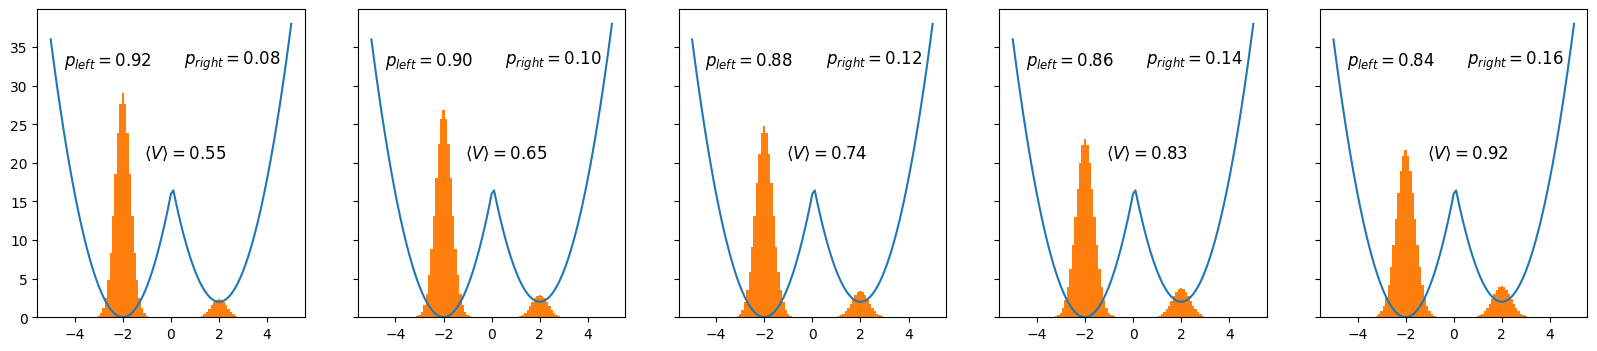

In [12]:
fig, axes = plt.subplots(1,5,figsize=(20,4), sharey=True)

pairs = []
for kT, ax in zip([0.8, 0.9, 1.0, 1.1, 1.2], axes):
	pot = DoubleWellPotential()
	xs = torch.arange(-5, 5.1, 0.1, dtype=torch.float64)
	system = MinEntropyDistribution(xs, pot, kT=kT, l=300)

	optimizer = torch.optim.Adam(system.parameters(), lr=0.05)
	steps = 20000
	for step in range(steps):
		optimizer.zero_grad() # wipe the previous calculated gradients
		loss, p = system()
		loss.backward()
		optimizer.step()
		if step % 2000 == 0:
			print(f'Step {step}, Loss: {loss}')
	pairs.append([system.energy, system.entropy])

	p_left = torch.sum(p[:51])*0.1
	p_right = torch.sum(p[51:101])*0.1
	ax.bar(xs.detach().numpy(), p.detach().numpy()*25, width=0.1, facecolor='C1')
	ax.text(0.1, 0.8, r'$p_{left}=$'+f'{p_left:.2f}\n',
		transform=ax.transAxes, ha='left', va='center', size=12)
	ax.text(0.55, 0.8, r'$p_{right}=$'+f'{p_right:.2f}\n',
		transform=ax.transAxes, ha='left', va='center', size=12)
	ax.text(0.4, 0.5, r'$\langle V \rangle=$'+f'{system.energy_target:.2f}\n',
	transform=ax.transAxes, ha='left', va='center', size=12)
	ax.plot(xs, pot(xs))
		

They agree very well with the previous optimization. In this code, the convergence toward the target was much slower, but increasing the learning rate solved the problem. 

In the first part, we "simply" had to minimize the free energy. This is just falling into a minimum in high-dimensional space, and the path there is totally arbitrary, i.e. the $p$'s can change however they like until they reach minimum.

In this second part, we gave an energy target and therefore essentially fixed the path toward minimum that the coefficients have to traverse. Think of the free-energy exercise in week 6, where we need to move along the fixed energy path to reach minimum.

In [9]:
import numpy as np

energies = []
entropies = []

for energy, entropy in pairs:
	energies.append(energy.detach().item())
	entropies.append(entropy.detach().item())

energies = np.array(energies)
entropies = np.array(entropies)

dE_dS = np.gradient(energies, entropies)

print("Energy:", energies)
print("Entropy:", entropies)
print("kBT:", dE_dS)

Energy: [0.55379284 0.64739395 0.7400704  0.83081836 0.91912523]
Entropy: [0.53828264 0.64825398 0.74571739 0.83208813 0.90884232]
kBT: [0.8511409  0.90401992 1.00379282 1.10354013 1.15051533]


Pretty accurate, except the endpoints, where numpy makes one-sided differences, i.e. simply the difference between endpoint and next point.

# W09H Dynamic equilibrium for three-body orbit

In [18]:
import torch
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
		# # velocity verlet
		# rs = []
		# for _ in range(N):
		# 	r = pos
		# 	v = vel
		# 	a_t = mdsys.force() # assume m=1

		# 	# 1. update position
		# 	r += v*dt + 1/2*a_t*dt**2
		# 	mdsys.set_position(r)

		# 	# 2. evaluate force and acceleration at new step
		# 	a_t_dt = mdsys.force() # for harmonic osciallor F = -kx

		# 	# 3. velocity update
		# 	v += 1/2 * (a_t + a_t_dt)*dt
		# 	mdsys.set_velocity(v)
		# 	rs.append(r)
		# return rs

In [19]:
class ThreeBodyOrbit(torch.nn.Module):
	def __init__(self, dt=0.00563433):
		super().__init__()
		self.r0 = torch.nn.Parameter(torch.tensor([-0.54, 0.33]))
		self.v0 = torch.nn.Parameter(torch.tensor([1.1, -0.22]))
		self.dt = dt

	def forward(self, N=333):
		pos0 = torch.stack([self.r0, torch.stack([ self.r0[0], -self.r0 [1]]), 
							 torch.stack([-2 * self.r0[0], torch.tensor(0.0)])
							])
		vel0 = torch.stack([self.v0, torch.stack([-self.v0[0], self.v0[1]]), 
							 torch.stack([torch.tensor(0.0), torch.tensor(-2 * self.v0[1])])
							])

		pos, vel = pos0, vel0
		dt = self.dt

		# YOUR CODE when implementing velocity -Verlet

		return pos, vel, pos0, vel0

system = ThreeBodyOrbit()

pos, vel, pos0, vel0 = system()
print(f'{pos0=}\n{vel0=}')

pos0=tensor([[-0.5400,  0.3300],
        [-0.5400, -0.3300],
        [ 1.0800,  0.0000]], grad_fn=<StackBackward0>)
vel0=tensor([[ 1.1000, -0.2200],
        [-1.1000, -0.2200],
        [ 0.0000,  0.4400]], grad_fn=<StackBackward0>)


C:\Users\emilk\AppData\Local\Temp\ipykernel_36468\4205667283.py:13: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.stack([torch.tensor(0.0), torch.tensor(-2 * self.v0[1])])


In [22]:
def compute_gravitational_forces(pos, G=1.0, m=1.0, eps=1e-7):
	N = pos.shape[0]
	force = torch.zeros_like(pos)

	for i in range(N):		#i'th particle
		for j in range(N):	#j'th particle acting on i'th particle
			if i == j:  
				continue
			r_ij = pos[j] - pos[i]	# r_ij = r_j - r_i
			sq_dist = torch.sum(r_ij**2)
			force[i] += G*m*m * r_ij/(sq_dist + eps**2)**(3/2)  # update i'th row
	return force

pos0 = torch.tensor([[-0.5400,  0.3300],
					 [-0.5400, -0.3300],
					 [ 1.0800,  0.0000]])
compute_gravitational_forces(pos0)

tensor([[ 0.3585, -2.3687],
        [ 0.3585,  2.3687],
        [-0.7170,  0.0000]])

### The Velocity Verlet integration loop

In [25]:
class ThreeBodyOrbit(torch.nn.Module):
	def __init__(self, dt=0.00563433):
		super().__init__()
		self.r0 = torch.nn.Parameter(torch.tensor([-0.54, 0.33]))
		self.v0 = torch.nn.Parameter(torch.tensor([1.1, -0.22]))
		self.dt = dt

	def forward(self, N=333):
		pos0 = torch.stack([self.r0, torch.stack([ self.r0[0], -self.r0 [1]]), 
							 torch.stack([-2 * self.r0[0], torch.tensor(0.0)])
							])
		vel0 = torch.stack([self.v0, torch.stack([-self.v0[0], self.v0[1]]), 
							 torch.stack([torch.tensor(0.0), torch.tensor(-2 * self.v0[1])])
							])

		pos, vel = pos0, vel0
		dt = self.dt

		# velocity verlet
		self.rs = []
		for _ in range(N):
			force = compute_gravitational_forces(pos)
			acc = force  # for m=1, f=ma

			# 1: positon update
			pos = pos + vel*dt + 1/2*acc*dt**2

			# 2: evaluate force (acceleration) at new step
			acc_dt = compute_gravitational_forces(pos)
	
			# 2: velocity update
			vel = vel + 1/2 * (acc + acc_dt)*dt

			self.rs.append(pos)

		return pos, vel, pos0, vel0

system = ThreeBodyOrbit()

pos, vel, pos0, vel0 = system()
print(f'{pos0=}\n{vel0=}')
print(f'{pos=}\n{vel=}')

pos0=tensor([[-0.5400,  0.3300],
        [-0.5400, -0.3300],
        [ 1.0800,  0.0000]], grad_fn=<StackBackward0>)
vel0=tensor([[ 1.1000, -0.2200],
        [-1.1000, -0.2200],
        [ 0.0000,  0.4400]], grad_fn=<StackBackward0>)
pos=tensor([[ 0.9455, -0.1476],
        [-0.5944,  0.3773],
        [-0.3512, -0.2297]], grad_fn=<AddBackward0>)
vel=tensor([[ 0.0645,  0.5093],
        [ 1.0979,  0.0077],
        [-1.1624, -0.5170]], grad_fn=<AddBackward0>)


C:\Users\emilk\AppData\Local\Temp\ipykernel_36468\3587654727.py:13: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.stack([torch.tensor(0.0), torch.tensor(-2 * self.v0[1])])


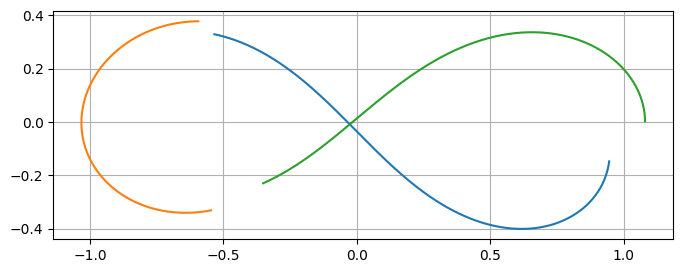

In [26]:
def plot_trajectory(model):
	fig, ax = plt.subplots(1,1,figsize=(8,4))

	particle1 = []
	particle2 = []
	particle3 = []

	for pos in model.rs:
		positions = pos.detach().numpy()
		particle1.append(positions[0])
		particle2.append(positions[1])
		particle3.append(positions[2])

	x1, y1 = zip(*particle1)
	x2, y2 = zip(*particle2)
	x3, y3 = zip(*particle3)


	ax.plot(x1, y1)
	ax.plot(x2, y2)
	ax.plot(x3, y3)
	ax.set_aspect('equal')
	ax.grid()

plot_trajectory(system)

### The loss function

$$L=\sum_i \left| r_i^{(final)}-r_{i-1}^{(initial)}\right|^2 + \sum_i \left| v_i^{(final)}-v_{i-1}^{(initial)}\right|^2$$

In [21]:
def periodic_loss(model):
	pos_final, vel_final, pos0, vel0 = model()
	pos_final = pos_final[[1, 2, 0], :]   	# cyclic rotation, as to get r_i - r_{i-1}
	vel_final = vel_final[[1, 2, 0], :]		# cyclic rotation, as to get v_i - v_{i-1}
	loss = torch.sum((pos_final - pos0)**2) + torch.sum((vel_final - vel0)**2)
	return loss

periodic_loss(system).data

C:\Users\emilk\AppData\Local\Temp\ipykernel_36468\4205667283.py:13: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.stack([torch.tensor(0.0), torch.tensor(-2 * self.v0[1])])


tensor(14.0334)

### Optimizing the orbit

In [ ]:
system50 = ThreeBodyOrbit()
optimizer = torch.optim.Adam(system50.parameters(), lr=0.001)

for step in range(50):
	optimizer.zero_grad()
	loss = periodic_loss(system50)
	loss.backward()
	optimizer.step()
	if (step+1) % 50 == 0 or step == 0:
		print(f"{step if step==0 else step+1:4d} Loss = {loss.item():.4f}")

C:\Users\emilk\AppData\Local\Temp\ipykernel_14024\4160069450.py:13: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.stack([torch.tensor(0.0), torch.tensor(-2 * self.v0[1])])


   0 Loss = 0.2437
  50 Loss = 0.0157


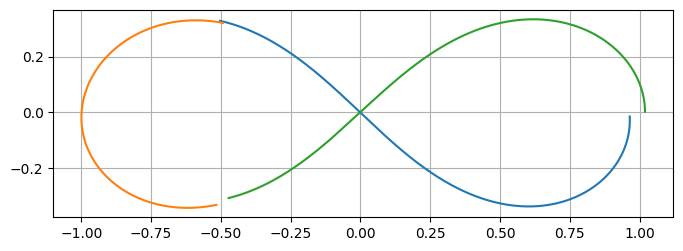

In [42]:
plot_trajectory(system50)

In [ ]:
system500 = ThreeBodyOrbit()
optimizer = torch.optim.Adam(system500.parameters(), lr=0.001)

for step in range(500):
	optimizer.zero_grad()
	loss = periodic_loss(system500)
	loss.backward()
	optimizer.step()
	if (step+1) % 50 == 0 or step == 0:
		print(f"{step if step==0 else step+1:4d} Loss = {loss.item():.4f}")

C:\Users\emilk\AppData\Local\Temp\ipykernel_14024\4160069450.py:13: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.stack([torch.tensor(0.0), torch.tensor(-2 * self.v0[1])])


   0 Loss = 0.2437
  50 Loss = 0.0157
 100 Loss = 0.0034
 150 Loss = 0.0017
 200 Loss = 0.0007
 250 Loss = 0.0003
 300 Loss = 0.0001
 350 Loss = 0.0000
 400 Loss = 0.0000
 450 Loss = 0.0000
 500 Loss = 0.0000


Parameter containing:
tensor([-0.5000,  0.3195], requires_grad=True)

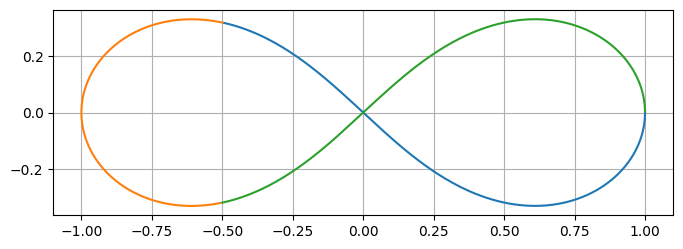

In [ ]:
plot_trajectory(system500)
system500.r0  # r0x = -0.5

### Optimize the timestep

To ensure $\Delta t$ can have any value, positive or negative, when being optimized, we make a nice trick, where the actual value is:

$f_{softplus}(x)=log(1+exp(x))$

To have $\Delta t=0.005$, the initial $x$ value in the above equation is $x=-5.2957$

C:\Users\emilk\AppData\Local\Temp\ipykernel_14024\1704598508.py:18: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.stack([torch.tensor(0.0), torch.tensor(-2 * self.v0[1])])


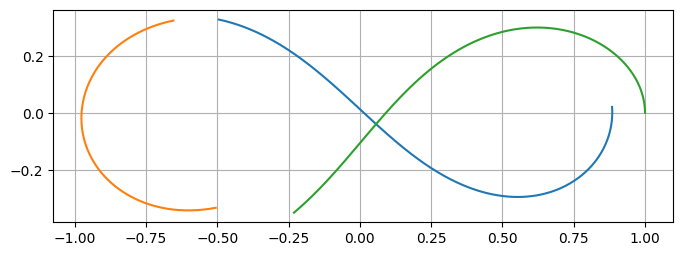

In [ ]:
class ThreeBodyOrbitOptTimestep(torch.nn.Module):
	def __init__(self):
		super().__init__()
		self.r0y = torch.nn.Parameter(torch.tensor(0.33))
		self.v0 = torch.nn.Parameter(torch.tensor([1.1, -0.22]))
		self._raw_dt = torch.nn.Parameter(torch.tensor(-5.2957))

	@property
	def dt(self):
		return torch.nn.functional.softplus(self._raw_dt)

	def forward(self, N=333):
		pos0 = torch.stack([torch.stack([torch.tensor(-0.5), self.r0y]), 
							torch.stack([torch.tensor(-0.5), -self.r0y]), 
							torch.stack([-2 * torch.tensor(-0.5), torch.tensor(0.0)])
							])
		vel0 = torch.stack([self.v0, torch.stack([-self.v0[0], self.v0[1]]), 
							 torch.stack([torch.tensor(0.0), torch.tensor(-2 * self.v0[1])])
							])

		pos, vel = pos0, vel0

		dt = self.dt

		# velocity verlet
		self.rs = []
		for _ in range(N):
			force = compute_gravitational_forces(pos)
			acc = force  # for m=1, f=ma

			# 1: positon update
			pos = pos + vel*dt + 1/2*acc*dt**2

			# 2: evaluate force (acceleration) at new step
			acc_dt = compute_gravitational_forces(pos)

			# 2: velocity update
			vel = vel + 1/2 * (acc + acc_dt)*dt

			self.rs.append(pos)

		return pos, vel, pos0, vel0

system = ThreeBodyOrbitOptTimestep()
pos, vel, pos0, vel0 = system()  # run 'forward()'
plot_trajectory(system)

In [ ]:
system_dt = ThreeBodyOrbitOptTimestep()
optimizer = torch.optim.Adam(system_dt.parameters(), lr=0.005)

for step in range(500):
	optimizer.zero_grad()
	loss = periodic_loss(system_dt)
	loss.backward()
	optimizer.step()
	if (step+1) % 50 == 0 or step == 0:
		print(f"{step if step==0 else step+1:4d} Loss = {loss.item():.4f}")

C:\Users\emilk\AppData\Local\Temp\ipykernel_14024\1951599719.py:18: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.stack([torch.tensor(0.0), torch.tensor(-2 * self.v0[1])])


   0 Loss = 0.6527
  50 Loss = 0.0066
 100 Loss = 0.0017
 150 Loss = 0.0007
 200 Loss = 0.0002
 250 Loss = 0.0001
 300 Loss = 0.0000
 350 Loss = 0.0000
 400 Loss = 0.0000
 450 Loss = 0.0000
 500 Loss = 0.0000


0.00563392


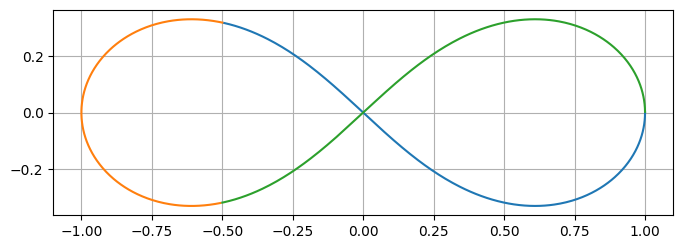

In [60]:
plot_trajectory(system_dt)
print(f'{system_dt.dt.data:.8f}')  # dt = 0.00563433

In this exercise I had to turn up the learning rate a bit, but we end up with approximately the same timestep


*Why is timestep an optimizeable parameter?*

### I want to try and find all optimal parameters:

C:\Users\emilk\AppData\Local\Temp\ipykernel_36468\1479440804.py:17: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.stack([torch.tensor(0.0), torch.tensor(-2 * self.v0[1])])


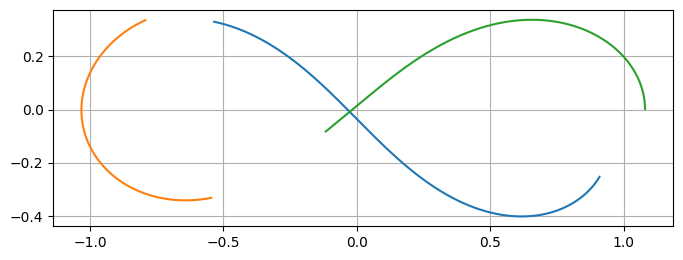

In [30]:
class ThreeBodyOrbitOptTimestep(torch.nn.Module):
	def __init__(self):
		super().__init__()
		self.r0 = torch.nn.Parameter(torch.tensor([-0.54, 0.33]))
		self.v0 = torch.nn.Parameter(torch.tensor([1.1, -0.22]))
		self._raw_dt = torch.nn.Parameter(torch.tensor(-5.2957))

	@property
	def dt(self):
		return torch.nn.functional.softplus(self._raw_dt)

	def forward(self, N=333):
		pos0 = torch.stack([self.r0, torch.stack([ self.r0[0], -self.r0 [1]]), 
							 torch.stack([-2 * self.r0[0], torch.tensor(0.0)])
							])
		vel0 = torch.stack([self.v0, torch.stack([-self.v0[0], self.v0[1]]), 
							 torch.stack([torch.tensor(0.0), torch.tensor(-2 * self.v0[1])])
							])

		pos, vel = pos0, vel0
		dt = self.dt

		# velocity verlet
		self.rs = []
		for _ in range(N):
			force = compute_gravitational_forces(pos)
			acc = force  # for m=1, f=ma

			# 1: positon update
			pos = pos + vel*dt + 1/2*acc*dt**2

			# 2: evaluate force (acceleration) at new step
			acc_dt = compute_gravitational_forces(pos)

			# 2: velocity update
			vel = vel + 1/2 * (acc + acc_dt)*dt

			self.rs.append(pos)

		return pos, vel, pos0, vel0

system_5p = ThreeBodyOrbitOptTimestep()
pos, vel, pos0, vel0 = system_5p()  # run 'forward()'
plot_trajectory(system_5p)

In [31]:
system_5p = ThreeBodyOrbitOptTimestep()
optimizer = torch.optim.Adam(system_5p.parameters(), lr=0.005)

for step in range(300):
	optimizer.zero_grad()
	loss = periodic_loss(system_5p)
	loss.backward()
	optimizer.step()
	if (step+1) % 50 == 0 or step == 0:
		print(f"{step if step==0 else step+1:4d} Loss = {loss.item():.4f}")

C:\Users\emilk\AppData\Local\Temp\ipykernel_36468\1479440804.py:17: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.stack([torch.tensor(0.0), torch.tensor(-2 * self.v0[1])])


   0 Loss = 1.2811
  50 Loss = 0.0124
 100 Loss = 0.0010
 150 Loss = 0.0000
 200 Loss = 0.0000
 250 Loss = 0.0000
 300 Loss = 0.0000


0.00548423


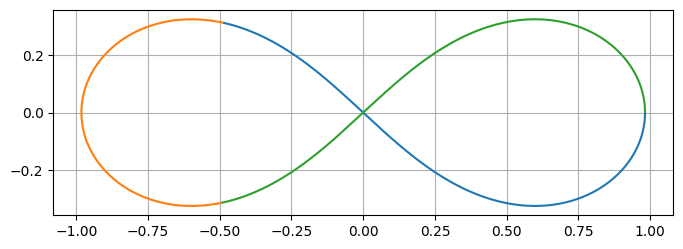

In [34]:
plot_trajectory(system_5p)
print(f'{system_5p.dt.data:.8f}')  # dt = 0.00563433

### Other stationary orbits

# W09I Derivatives of functions

In [ ]:
import torch
import matplotlib.pyplot as plt

### Polynomial

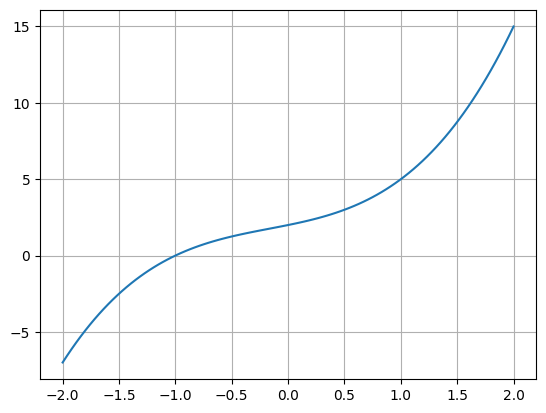

In [ ]:
def polynomial(x, a=1, b=1/2, c=3/2, d=2):
	y = a*x**3 + b*x**2 + c*x + d
	return y

fig, ax = plt.subplots()
xs = torch.linspace(-2,2, 100)
ys = polynomial(xs)
ax.plot(xs, ys)
ax.grid()

### Automatic differentiation

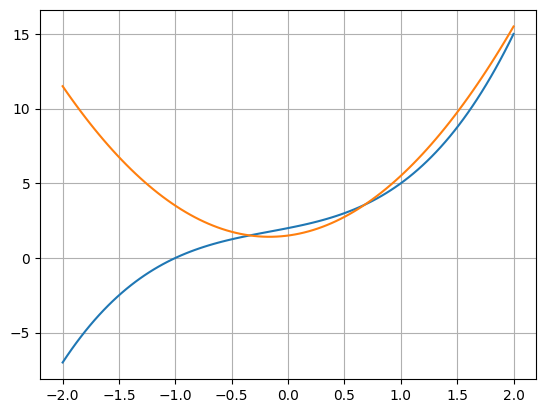

In [82]:
xs = torch.linspace(-2, 2, 100, requires_grad=True)
ys = polynomial(xs)
yps = torch.autograd.grad(ys, xs, torch.ones_like(xs))[0]
xs = xs.detach().numpy()
ys = ys.detach().numpy()
yps = yps.detach().numpy()

fig, ax = plt.subplots()
ax.plot(xs, ys)
ax.plot(xs, yps)
ax.grid()


Plot a few points from the analytical solution

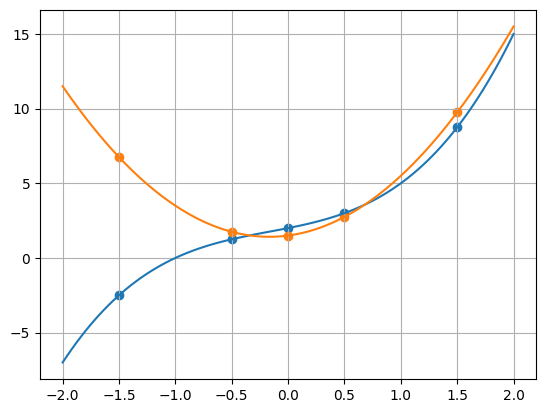

In [ ]:
def polygrad(x, a=1, b=1/2, c=3/2):
	yp = 3*a*x**2 + 2*b*x + c
	return yp

x_points = torch.tensor([-1.5, -0.5, 0.0, 0.5, 1.5])
y_points = polynomial(x_points)
yp_points = polygrad(x_points)

fig, ax = plt.subplots()
ax.plot(xs, ys)
ax.scatter(x_points, y_points, c='C0')
ax.plot(xs, yps)
ax.scatter(x_points, yp_points, c='C1')
ax.grid()

### Higher derivatives

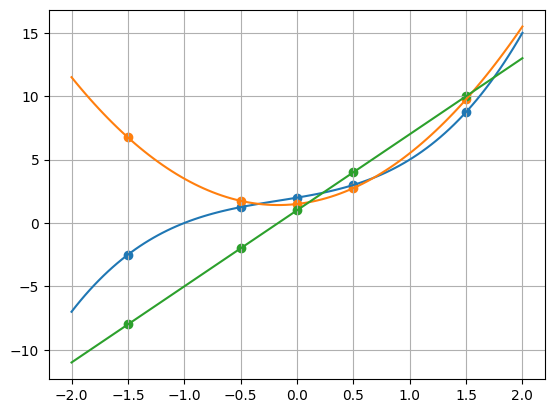

In [ ]:
xs = torch.linspace(-2, 2, 100, requires_grad=True)
ys = polynomial(xs)
yps = torch.autograd.grad(ys, xs, torch.ones_like(xs), create_graph=True)[0]
ypps = torch.autograd.grad(yps, xs, grad_outputs=torch.ones_like(xs))[0]
xs = xs.detach().numpy()
ys = ys.detach().numpy()
yps = yps.detach().numpy()
ypps = ypps.detach().numpy()


def poly2grad(x, a=1, b=1/2):
	ypp = 6*a*x + 2*b
	return ypp

x_points = torch.tensor([-1.5, -0.5, 0.0, 0.5, 1.5])
y_points = polynomial(x_points)
yp_points = polygrad(x_points)
ypp_points = poly2grad(x_points)

fig, ax = plt.subplots()
ax.plot(xs, ys)
ax.scatter(x_points, y_points, c='C0')
ax.plot(xs, yps)
ax.scatter(x_points, yp_points, c='C1')
ax.plot(xs, ypps)
ax.scatter(x_points, ypp_points, c='C2')
ax.grid()
# ax.set_ylim(-10,10)